# Session 7 — Demo 1 — How clustering thinks

**What this demo covers.** Every model so far had an answer column: the time a task took, bankrupt or not. Tonight the answer column is gone, and the question becomes *what groups are in here?* That is **clustering**. We run k-means by hand on eight points, then let scikit-learn do it. We watch it cut a cloud that has no groups at all, see how units of measurement decide the result, and pick the number of groups with two advisors. Then other ideas of what a group is: **DBSCAN**, which looks for dense areas and leaves the loners out; **HDBSCAN**, its easier-to-use successor; and **hierarchical clustering**, which builds a family tree of points. At the end, four algorithms on four shapes, side by side, and the list of things that go wrong.

**Data.** Toy points made up in this notebook; two ratios of the Taiwan companies (sessions 5 and 6), with the bankruptcy column left alone; toy shapes from scikit-learn.

**How to run.** Locally: top to bottom. Colab: uncomment the two `git clone` lines in the setup cell. Everything used here is preinstalled in Colab.

## 0. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator

# the Taiwan bankruptcy dataset (sessions 5 to 7)
BANKRUPTCY = Path("../../data/bankruptcy")

# --- Google Colab? Uncomment these lines to fetch the course repo: ---
# !git clone https://github.com/seemsGoodNow/hse-data-science-course.git course
# BANKRUPTCY = Path("course/data/bankruptcy")

# one colour per cluster; grey is kept for "noise" (points in no cluster)
CLUSTER_COLORS = [
    "#4a7ebb",
    "#c0392b",
    "#27ae60",
    "#8e44ad",
    "#e67e22",
    "#16a085",
    "#d35400",
    "#2c3e50",
]
NOISE_COLOR = "#b9c2cf"
CENTER_COLOR = "#1a2233"

In [2]:
def make_ax_better(ax, minor=""):
    """Tidy one chart: drop the top/right frame, add a light grid.

    minor="x", "y" or "xy" also adds small ticks between the labelled ones.
    """
    ax.spines["right"].set_visible(False)
    ax.spines["top"].set_visible(False)
    if "x" in minor:
        ax.xaxis.set_minor_locator(AutoMinorLocator())
    if "y" in minor:
        ax.yaxis.set_minor_locator(AutoMinorLocator())
    if minor:
        ax.tick_params(which="minor", length=2.5)
        ax.tick_params(which="major", length=5)
        ax.grid(which="minor", linewidth=0.15, color="tab:grey", alpha=0.25)
    ax.grid(linewidth=0.5, color="tab:grey", alpha=0.25)


def draw_clusters(ax, points, labels):
    """Scatter a two-column table, one colour per cluster.

    labels holds one cluster number per row; -1 means noise and is drawn grey.
    """
    x_column, y_column = points.columns
    labels = np.asarray(labels)
    for cluster in sorted(set(labels)):
        in_cluster = labels == cluster
        if cluster == -1:
            color = NOISE_COLOR
            name = "noise"
        else:
            # % is the remainder of a division: colours repeat after 8 clusters
            color = CLUSTER_COLORS[cluster % len(CLUSTER_COLORS)]
            name = f"cluster {cluster}"
        ax.scatter(
            points.loc[in_cluster, x_column],
            points.loc[in_cluster, y_column],
            s=10,
            color=color,
            label=name,
        )

`draw_clusters` is a small helper for this notebook: it gives every cluster its own colour, so we don't repeat the same loop under every chart. It takes a table with two columns (the two axes) and one cluster number per row.

## 1. A task with no answer column

Put the three kinds of task side by side:

| task | what goes in | what comes out | can we count mistakes? |
|---|---|---|---|
| **regression** (session 5) | features X | a number: minutes per task | yes, we know the real minutes |
| **classification** (sessions 5 and 6) | features X | one of known labels: bankrupt or not | yes, we know who went bankrupt |
| **clustering** (tonight) | features X | groups that nobody named in advance | no: there is no right answer to compare with |

The first two are called **supervised learning**: a teacher (the answer column) tells the model when it is wrong. Clustering is **unsupervised**: no teacher. That changes how we judge the result. There is no accuracy and no AUC. A clustering is good when you can **name** each group, **do something different** with each group, and get roughly the same groups again on fresh data.

Where it shows up in a business: customer segments for different offers, the topics of ten thousand complaints, "branches like this one" for a fair comparison, shares that move together, a day or a client that fits no group at all (an anomaly).

## 2. k-means by hand

**k-means** is the most popular clustering algorithm. You choose **k**, the number of groups. Then it repeats two steps:

1. **Assign:** every point joins its nearest center.
2. **Move:** every center moves to the average of its points.

It stops when nothing moves. "Nearest" means the straight-line distance on the chart, Pythagoras from school: $\sqrt{(x - x_c)^2 + (y - y_c)^2}$. `np.sqrt` is the square root.

🧪 **Toy example:** eight points, two obvious groups. We start the two centers in a bad place on purpose: both on the left.

In [3]:
toy_points = pd.DataFrame({
    "x": [1.0, 1.5, 2.0, 1.2, 6.0, 6.5, 7.0, 6.2],
    "y": [1.0, 2.0, 1.2, 1.6, 5.0, 6.0, 5.2, 5.8],
})

# two starting centers, both badly placed on the left
toy_centers = pd.DataFrame(
    {"x": [1.0, 2.0], "y": [1.0, 1.2]},
    index=["A", "B"],
)
toy_centers

,x,y
A,1.0,1.0
B,2.0,1.2


One round of k-means as a function. It returns the points with their distances and cluster, and the new centers.

In [4]:
def run_one_round(points, centers):
    """Assign every point to its nearest center, then move each center."""
    assigned = points.copy()
    for name in centers.index:
        assigned[f"distance_to_{name}"] = np.sqrt(
            (assigned["x"] - centers.loc[name, "x"]) ** 2
            + (assigned["y"] - centers.loc[name, "y"]) ** 2
        )
    assigned["cluster"] = np.where(
        assigned["distance_to_A"] <= assigned["distance_to_B"],
        "A",
        "B",
    )
    new_centers = assigned.groupby("cluster")[["x", "y"]].mean()
    return assigned, new_centers


round_1_points, round_1_centers = run_one_round(toy_points, toy_centers)
round_1_points.round(2)

,x,y,distance_to_A,distance_to_B,cluster
0,1.0,1.0,0.00,1.02,A
1,1.5,2.0,1.12,0.94,B
2,2.0,1.2,1.02,0.00,B
3,1.2,1.6,0.63,0.89,A
4,6.0,5.0,6.40,5.52,B
5,6.5,6.0,7.43,6.58,B
6,7.0,5.2,7.32,6.40,B
7,6.2,5.8,7.08,6.23,B


Read the last column. Points 0 and 3 are closer to A. Point 1 and point 2 are a little closer to B, and so is the whole right-hand group (rows 4 to 7): it is far from both centers, but B sits slightly further right. So B collects six points, two on the left and four on the right. Now the move step:

In [5]:
round_1_centers.round(2)

,x,y
cluster,,
A,1.10,1.3
B,4.87,4.2


B's center jumped right, to the average of its six points, somewhere between the two groups. A moved to the middle of points 0 and 3. Two more rounds:

In [6]:
round_2_points, round_2_centers = run_one_round(toy_points, round_1_centers)
round_3_points, round_3_centers = run_one_round(toy_points, round_2_centers)
round_2_centers.round(2)

,x,y
cluster,,
A,1.42,1.45
B,6.42,5.50


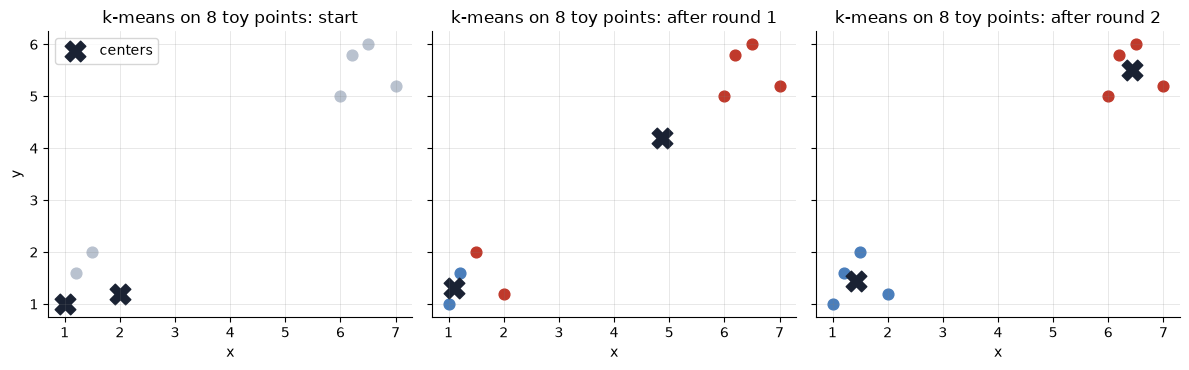

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharex=True, sharey=True)
rounds = [
    ("start", toy_points.assign(cluster="?"), toy_centers),
    ("after round 1", round_1_points, round_1_centers),
    ("after round 2", round_2_points, round_2_centers),
]
cluster_colors = [
    ("A", CLUSTER_COLORS[0]),
    ("B", CLUSTER_COLORS[1]),
    ("?", NOISE_COLOR),
]
for ax, (title, points, centers) in zip(axes, rounds):
    for cluster, color in cluster_colors:
        in_cluster = points["cluster"] == cluster
        ax.scatter(
            points.loc[in_cluster, "x"],
            points.loc[in_cluster, "y"],
            s=60,
            color=color,
        )
    ax.scatter(
        centers["x"],
        centers["y"],
        marker="X",
        s=220,
        color=CENTER_COLOR,
        label="centers",
    )
    ax.set_title(f"k-means on 8 toy points: {title}")
    ax.set_xlabel("x")
    make_ax_better(ax)
axes[0].set_ylabel("y")
axes[0].legend(loc="upper left")
plt.tight_layout()
plt.show()

Two rounds and the centers sit in the middle of the two groups, even from a bad start. Round 3 gives the same centers as round 2 (check `round_3_centers`): nothing moves, so k-means stops.

**Now the same with scikit-learn.** `KMeans(n_clusters=2)` is the algorithm with k = 2. `.fit(table)` runs the rounds until nothing moves. Two more settings:

- `n_init=10`: start from 10 different random sets of centers and keep the best result. k-means can get stuck in a bad answer from an unlucky start, so we try several starts.
- `random_state=42`: fixes the randomness, as in session 6's splits, so the result is the same every run.

What the model learned is stored in attributes whose names **end with `_`** (this is how scikit-learn marks "learned during `.fit`"): `labels_` is the cluster of every row, `cluster_centers_` holds the centers.

In [8]:
from sklearn.cluster import KMeans

toy_kmeans = KMeans(n_clusters=2, n_init=10, random_state=42)
toy_kmeans.fit(toy_points)

print(
    f"cluster of each point: {toy_kmeans.labels_}\n"
    f"centers:\n{toy_kmeans.cluster_centers_.round(2)}"
)

cluster of each point: [0 0 0 0 1 1 1 1]
centers:
[[1.42 1.45]
 [6.42 5.5 ]]


The same two groups and the same centers as our hand-made rounds. scikit-learn numbers the clusters 0 and 1 instead of A and B; the numbers are just names and carry no order.

## 3. k-means always returns k groups

Back to the Taiwan companies. Take two ratios every financier reads: the debt ratio and the return on assets (ROA). **We do not touch the bankruptcy column.** Remember from session 5 that these ratios were published rescaled to the range 0 to 1: read directions (more debt, more profit), not units.

In [9]:
companies = pd.read_csv(BANKRUPTCY / "taiwan_bankruptcy.csv")
companies.columns = companies.columns.str.strip()

ratios = companies[[
    "Debt ratio %",
    "ROA(C) before interest and depreciation before interest",
]]
ratios.columns = ["debt_ratio", "roa"]
ratios.describe().round(3)

,debt_ratio,roa
count,6819.000,6819.000
mean,0.113,0.505
std,0.054,0.061
min,0.000,0.000
25%,0.073,0.477
50%,0.111,0.503
75%,0.149,0.536
max,1.000,1.000


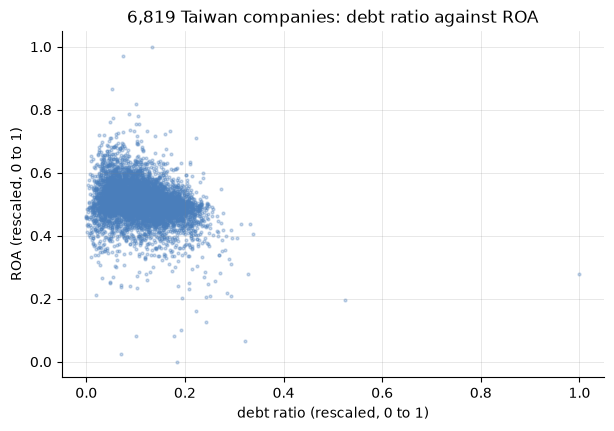

In [10]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(
    ratios["debt_ratio"],
    ratios["roa"],
    s=4,
    alpha=0.3,
    color=CLUSTER_COLORS[0],
)
ax.set_title("6,819 Taiwan companies: debt ratio against ROA")
ax.set_xlabel("debt ratio (rescaled, 0 to 1)")
ax.set_ylabel("ROA (rescaled, 0 to 1)")
make_ax_better(ax)
plt.show()

**Before running anything: how many groups do you see?** Take ten seconds.

Most people see one cloud with a few strays. Now ask k-means for three groups:

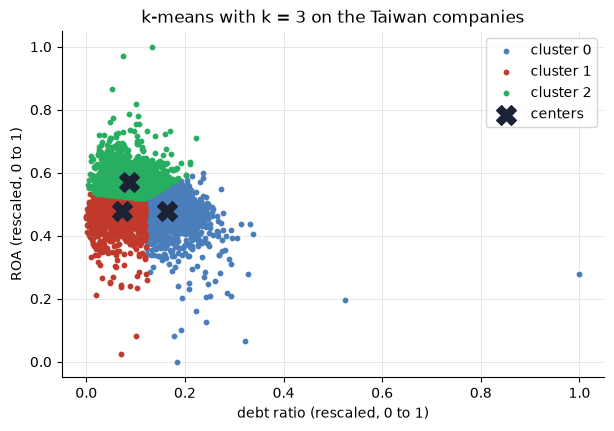

,debt_ratio,roa
0,0.164,0.480
1,0.073,0.478
2,0.087,0.570


In [11]:
taiwan_kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
taiwan_kmeans.fit(ratios)

fig, ax = plt.subplots(figsize=(7, 4.5))
draw_clusters(ax, ratios, taiwan_kmeans.labels_)
ax.scatter(
    taiwan_kmeans.cluster_centers_[:, 0],
    taiwan_kmeans.cluster_centers_[:, 1],
    marker="X",
    s=200,
    color=CENTER_COLOR,
    label="centers",
)
ax.set_title("k-means with k = 3 on the Taiwan companies")
ax.set_xlabel("debt ratio (rescaled, 0 to 1)")
ax.set_ylabel("ROA (rescaled, 0 to 1)")
ax.legend()
make_ax_better(ax)
plt.show()

taiwan_centers = pd.DataFrame(
    taiwan_kmeans.cluster_centers_,
    columns=["debt_ratio", "roa"],
)
taiwan_centers.round(3)

`cluster_centers_[:, 0]` means "all rows, first column" of the centers: the x coordinate of every center. `[:, 1]` is the y coordinate.

k-means did exactly what we asked: three groups. It cut one cloud into three slices, like a cake. Reading the centers honestly: one slice has less debt, one has more debt, one has higher profit. These are slices, not three kinds of companies.

**This is the first lesson of clustering: the algorithm always returns k groups, even when the data has none.** Nothing in the output warns you. The only defence is to look, and to ask whether the groups mean something.

## 4. Units decide the distances

k-means measures distances. If one column is in thousands and another in single digits, the big column decides almost everything. Let's break it on purpose.

🧪 **Toy example:** 400 made-up employees, two real groups: juniors (low salary, few years) and seniors (a higher salary, many years). Salary is in thousands of rubles, experience in years. `rng.normal(mean, spread, count)` draws random numbers around a mean (session 4's simulations).

In [12]:
rng = np.random.default_rng(0)
toy_people = pd.DataFrame({
    "salary_thousands": np.concatenate([
        rng.normal(90, 15, 200),
        rng.normal(130, 25, 200),
    ]),
    "years": np.concatenate([
        rng.normal(4, 1, 200),
        rng.normal(12, 2.5, 200),
    ]),
})
toy_people.describe().round(1)

,salary_thousands,years
count,400.0,400.0
mean,109.0,8.0
std,28.1,4.4
min,35.7,0.1
25%,89.2,4.0
50%,104.9,6.0
75%,125.1,11.9
max,206.7,18.2


We cluster twice: on the raw columns, and after standardizing each column (session 5's `(x - mean) / std`, done by session 6's `StandardScaler`). Standardizing puts both columns on the same footing: one unit is one standard deviation.

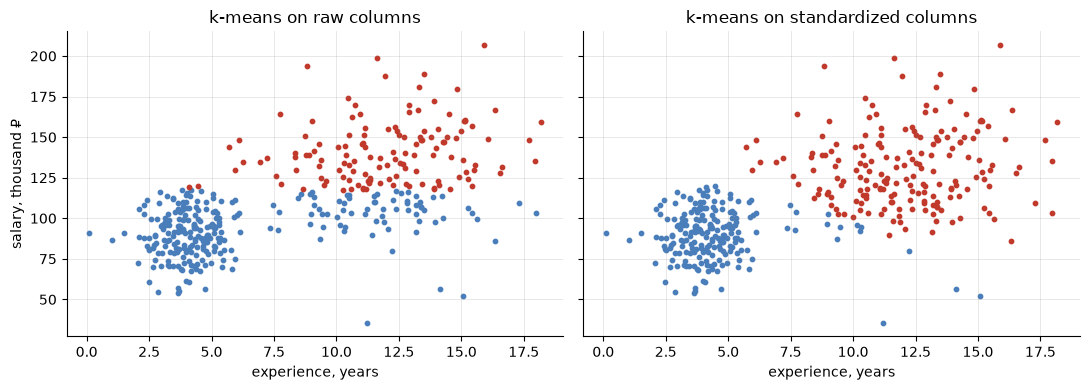

salary spread (std): 28 thousand ₽
experience spread (std): 4.4 years


In [13]:
from sklearn.preprocessing import StandardScaler

raw_kmeans = KMeans(n_clusters=2, n_init=10, random_state=42)
raw_labels = raw_kmeans.fit(toy_people).labels_

toy_people_scaled = StandardScaler().fit_transform(toy_people)
scaled_kmeans = KMeans(n_clusters=2, n_init=10, random_state=42)
scaled_labels = scaled_kmeans.fit(toy_people_scaled).labels_

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, labels, title in [
    (axes[0], raw_labels, "k-means on raw columns"),
    (axes[1], scaled_labels, "k-means on standardized columns"),
]:
    draw_clusters(ax, toy_people[["years", "salary_thousands"]], labels)
    ax.set_title(title)
    ax.set_xlabel("experience, years")
    make_ax_better(ax)
axes[0].set_ylabel("salary, thousand ₽")
plt.tight_layout()
plt.show()

print(
    f"salary spread (std): {toy_people['salary_thousands'].std():.0f} thousand ₽\n"
    f"experience spread (std): {toy_people['years'].std():.1f} years"
)

On the raw chart the border between the clusters runs almost flat, at one salary level, and cuts through the seniors. Count to be sure: we built the table ourselves, so we know that the first 200 rows are juniors and the last 200 seniors. `np.repeat` (session 5) writes each label 200 times, and `pd.crosstab` (session 4) puts the true group against the cluster.

In [14]:
true_group = pd.Series(np.repeat(["junior", "senior"], 200), name="true group")

raw_check = pd.crosstab(true_group, pd.Series(raw_labels, name="raw run"))
scaled_check = pd.crosstab(
    true_group,
    pd.Series(scaled_labels, name="standardized run"),
)
print(raw_check, "\n")
print(scaled_check)

raw run       0    1
true group          
junior      198    2
senior       71  129 

standardized run    0    1
true group                
junior            200    0
senior             15  185


Each row is a real group, each column a cluster (0 and 1 are just names). The raw run puts 71 seniors into the juniors' cluster: it splits mostly by salary, so seniors with a modest salary land with the juniors. The standardized run makes 15 such mistakes.

Why? The salary column spreads about 6 times wider than experience. On the raw columns, 10 thousand rubles of salary count exactly as much as 10 years of experience. Ten years is a whole career; 10 thousand rubles is a small raise. So the raw run hardly looks at experience. On a chart this is easy to miss, which is why we counted.

**Rule: before any distance-based method, put the columns on one scale.** The Taiwan ratios were already on 0 to 1. The complaint vectors in Demo 3 come out of the encoder on one scale. Check every time.

## 5. Who chooses k? You do, with two advisors

Two numbers help to choose k. Both are computed for k = 2, 3, 4 and so on, and you look at how they change.

- **Inertia** (`.inertia_`): the sum of squared distances from every point to its center. Small = tight groups. It always falls when k grows (with k = number of points it is 0), so we don't look for the minimum. We look for the **elbow**: the k after which adding a group stops helping much.
- **Silhouette** (`silhouette_score`): for every point, compare the average distance to its own cluster (call it *a*) with the average distance to the nearest other cluster (*b*): $(b - a) / \max(a, b)$. Near 1: the point clearly belongs to its group. Near 0: it sits on a border. The score is the average over all points. Higher is better.

🧪 **Toy example first, where the answer is known:** `make_blobs` from scikit-learn draws points around the centers we give it. We give 3 centers, so the right k is 3.

In [15]:
from sklearn.datasets import make_blobs
from sklearn.metrics import silhouette_score

blob_array, _ = make_blobs(
    n_samples=300,
    centers=[[0, 0], [5, 0], [2.5, 4]],
    cluster_std=0.8,
    random_state=1,
)
toy_blobs = pd.DataFrame(blob_array, columns=["x", "y"])

k_values = list(range(2, 9))
blob_inertia = []
blob_silhouette = []
for k in k_values:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42).fit(toy_blobs)
    blob_inertia.append(kmeans.inertia_)
    blob_silhouette.append(silhouette_score(toy_blobs, kmeans.labels_))

`make_blobs` returns two things: the points and the true blob of each point. We keep the points and throw the true labels into `_`, a name that means "not needed". A clustering never gets the labels. In the next cell, `np.argmax` returns the position of the largest number in a list, so `k_values[...]` at that position is the k with the best silhouette.

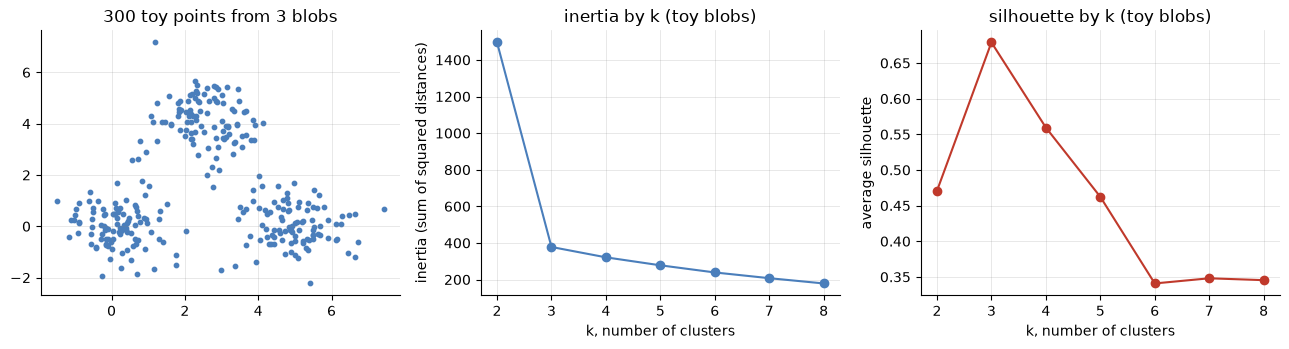

best silhouette at k = 3


In [16]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
draw_clusters(axes[0], toy_blobs, np.zeros(len(toy_blobs), dtype=int))
axes[0].set_title("300 toy points from 3 blobs")
axes[1].plot(k_values, blob_inertia, marker="o", color=CLUSTER_COLORS[0])
axes[1].set_title("inertia by k (toy blobs)")
axes[1].set_ylabel("inertia (sum of squared distances)")
axes[2].plot(k_values, blob_silhouette, marker="o", color=CLUSTER_COLORS[1])
axes[2].set_title("silhouette by k (toy blobs)")
axes[2].set_ylabel("average silhouette")
for ax in axes[1:]:
    ax.set_xlabel("k, number of clusters")
for ax in axes:
    make_ax_better(ax)
plt.tight_layout()
plt.show()

best_blob_k = k_values[int(np.argmax(blob_silhouette))]
print(f"best silhouette at k = {best_blob_k}")

Both advisors agree: the inertia line bends sharply at k = 3, and the silhouette is highest at k = 3. With real groups, they work.

**Now the Taiwan cloud.** Silhouette compares every point with every other point, which gets slow on 6,819 companies, so `sample_size=2000` computes it on a random 2,000 of them.

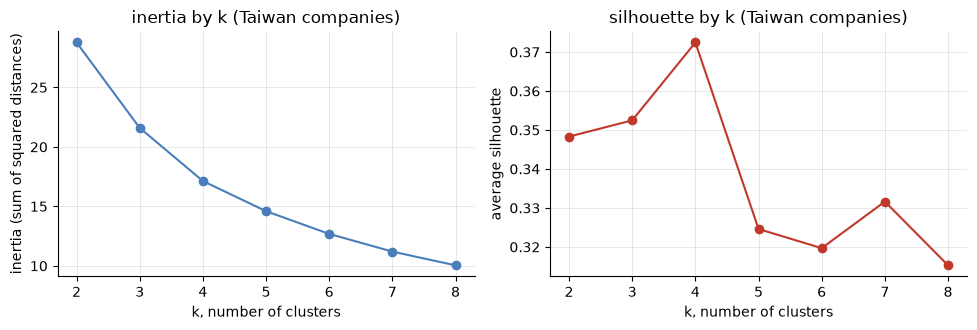

best silhouette at k = 4: 0.37
toy blobs, for comparison: 0.68


In [17]:
taiwan_inertia = []
taiwan_silhouette = []
for k in k_values:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42).fit(ratios)
    taiwan_inertia.append(kmeans.inertia_)
    taiwan_silhouette.append(
        silhouette_score(
            ratios,
            kmeans.labels_,
            sample_size=2000,
            random_state=0,
        )
    )

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].plot(k_values, taiwan_inertia, marker="o", color=CLUSTER_COLORS[0])
axes[0].set_title("inertia by k (Taiwan companies)")
axes[0].set_ylabel("inertia (sum of squared distances)")
axes[1].plot(k_values, taiwan_silhouette, marker="o", color=CLUSTER_COLORS[1])
axes[1].set_title("silhouette by k (Taiwan companies)")
axes[1].set_ylabel("average silhouette")
for ax in axes:
    ax.set_xlabel("k, number of clusters")
    make_ax_better(ax)
plt.tight_layout()
plt.show()

best_taiwan_k = k_values[int(np.argmax(taiwan_silhouette))]
print(
    f"best silhouette at k = {best_taiwan_k}: {max(taiwan_silhouette):.2f}\n"
    f"toy blobs, for comparison: {max(blob_silhouette):.2f}"
)

No sharp elbow: the inertia line bends smoothly. The silhouette prefers a different k than our 3, and its best value is much lower than on the toy blobs. That is the data telling you there are no natural groups here.

**So who chooses k?** The advisors give a range and a warning. The final k is a business decision: the number of groups you can **name** and **act on**. If a credit department needs three risk tiers, k = 3 is fine, as long as you say "these are three slices of one cloud, chosen for convenience", not "we discovered three kinds of firms".

## 6. A different idea of a group: dense areas (DBSCAN)

k-means thinks a group is a round blob around a center. Many real groups are not round.

🧪 **Toy example:** `make_moons` draws two interlocking half-moons. Two groups, obvious to the eye.

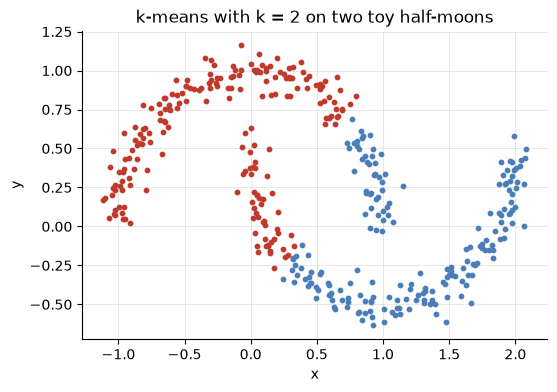

In [18]:
from sklearn.datasets import make_moons

moon_array, _ = make_moons(n_samples=400, noise=0.07, random_state=0)
toy_moons = pd.DataFrame(moon_array, columns=["x", "y"])

moon_kmeans = KMeans(n_clusters=2, n_init=10, random_state=42).fit(toy_moons)

fig, ax = plt.subplots(figsize=(6, 4))
draw_clusters(ax, toy_moons, moon_kmeans.labels_)
ax.set_title("k-means with k = 2 on two toy half-moons")
ax.set_xlabel("x")
ax.set_ylabel("y")
make_ax_better(ax)
plt.show()

k-means cuts straight across: each center grabs the nearest half of the picture, because "nearest center" can only draw straight borders.

**DBSCAN** has a different idea: *a group is an area where points stand close together*. Two settings:

- `eps`: a radius. Two points closer than `eps` are neighbours.
- `min_samples`: a point with at least this many neighbours inside its radius (counting itself) is a **core** point, the heart of a crowd.

Core points that are neighbours join one cluster, and the cluster grows through chains of neighbours. A point near a core point joins its cluster. A point near no core point is **noise**: it gets the label `-1` and belongs to no cluster. Two consequences: you never choose k (DBSCAN finds as many groups as there are crowds), and loners are named, not forced into a group. That makes DBSCAN a simple **anomaly detector**.

**How to choose `eps`.** Fix `min_samples` (5 is a common start). For every point, find the distance to its 5th nearest point. Sort these distances and draw them. Most points sit inside crowds, so the distances stay small; at the edge of the crowds the line shoots up. A good `eps` sits at that bend. `NearestNeighbors` from scikit-learn finds the nearest points; `.kneighbors` returns two tables (distances and positions), and we keep the distances. Like DBSCAN, it counts the point itself as its own first neighbour, so the two settings match.

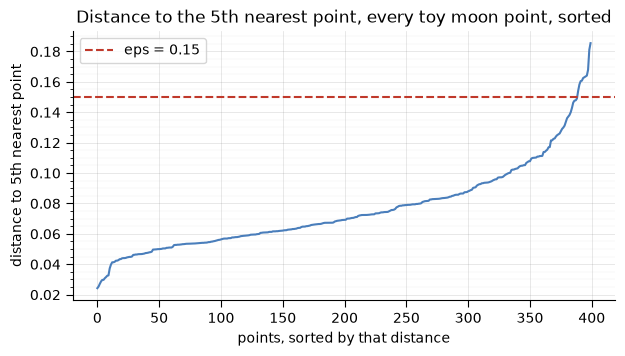

In [19]:
from sklearn.neighbors import NearestNeighbors

MIN_SAMPLES = 5
neighbours = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(toy_moons)
distances, _ = neighbours.kneighbors(toy_moons)

# distance from each point to its 5th nearest point, smallest first
fifth_neighbour_distance = np.sort(distances[:, MIN_SAMPLES - 1])

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(fifth_neighbour_distance, color=CLUSTER_COLORS[0])
ax.axhline(0.15, color=CLUSTER_COLORS[1], linestyle="--", label="eps = 0.15")
ax.set_title("Distance to the 5th nearest point, every toy moon point, sorted")
ax.set_xlabel("points, sorted by that distance")
ax.set_ylabel("distance to 5th nearest point")
ax.legend()
make_ax_better(ax, minor="y")
plt.show()

`distances[:, MIN_SAMPLES - 1]` takes column number 4, the 5th neighbour, for all rows (counting starts at 0). `np.sort` sorts the numbers from small to large.

The line climbs slowly up to about 0.12, then shoots up: those last points are the loners at the edges. We take `eps = 0.15` and try a smaller and a larger value to see what the setting does:

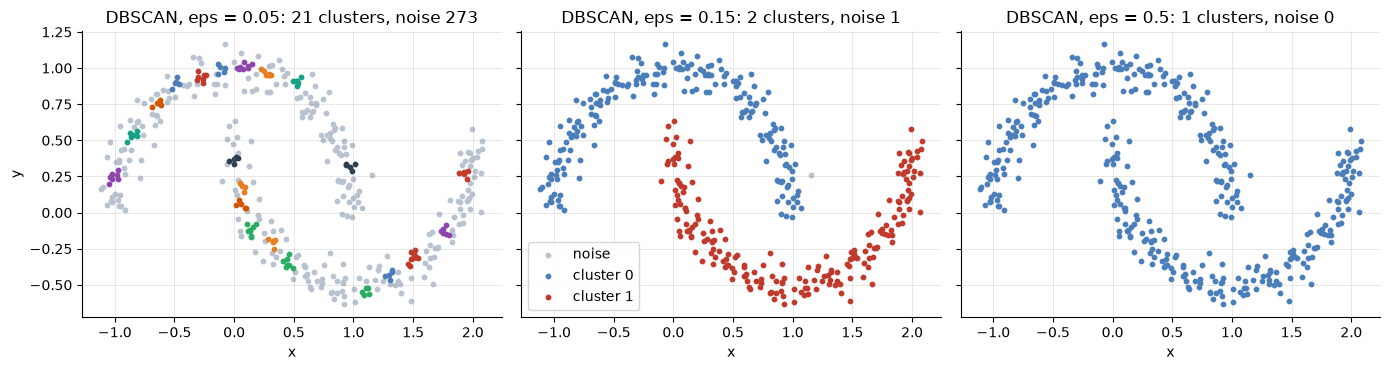

In [20]:
from sklearn.cluster import DBSCAN

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, eps in zip(axes, [0.05, 0.15, 0.5]):
    dbscan = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit(toy_moons)
    draw_clusters(ax, toy_moons, dbscan.labels_)
    found_clusters = len(set(dbscan.labels_) - {-1})
    noise_points = int((dbscan.labels_ == -1).sum())
    ax.set_title(
        f"DBSCAN, eps = {eps}: {found_clusters} clusters, noise {noise_points}"
    )
    ax.set_xlabel("x")
    make_ax_better(ax)
axes[0].set_ylabel("y")
axes[1].legend(loc="lower left")
plt.tight_layout()
plt.show()

`set(labels) - {-1}` is the set of cluster numbers without the noise label, and `len` counts them.

- **Too small** (0.05): almost nobody has five neighbours that close. Most points become noise, the rest split into many crumbs.
- **At the bend** (0.15): the two moons, exactly, and a handful of loners.
- **Too large** (0.5): everybody is everybody's neighbour, one big cluster.

DBSCAN has its own weak spot: one `eps` for the whole picture. If one group is dense and another sparse, no single radius fits both. **HDBSCAN**, its newer cousin, fixes exactly this, and with fewer settings to choose.

## 7. The practical default: HDBSCAN

DBSCAN's two settings show what "dense" means, which is why we met it first. In practice, a newer method is easier to use: **HDBSCAN** (hierarchical DBSCAN). It tries every radius at once, from tiny to huge, and keeps the groups that survive across many radii. So:

- **no `eps` to tune.** The radius is not one number for the whole picture, so a tight group and a loose group can be found together;
- **one main setting, `min_cluster_size`**: the smallest group you care about. It reads like a business sentence: "a segment of fewer than 20 clients is no use to me";
- loners still become **noise**, label `-1`, as in DBSCAN.

🧪 **Toy example:** three blobs of very different density, one tight, one loose, one in between. The same DBSCAN as before, then HDBSCAN with `min_cluster_size=20`, and the same HDBSCAN on the moons, without changing anything.

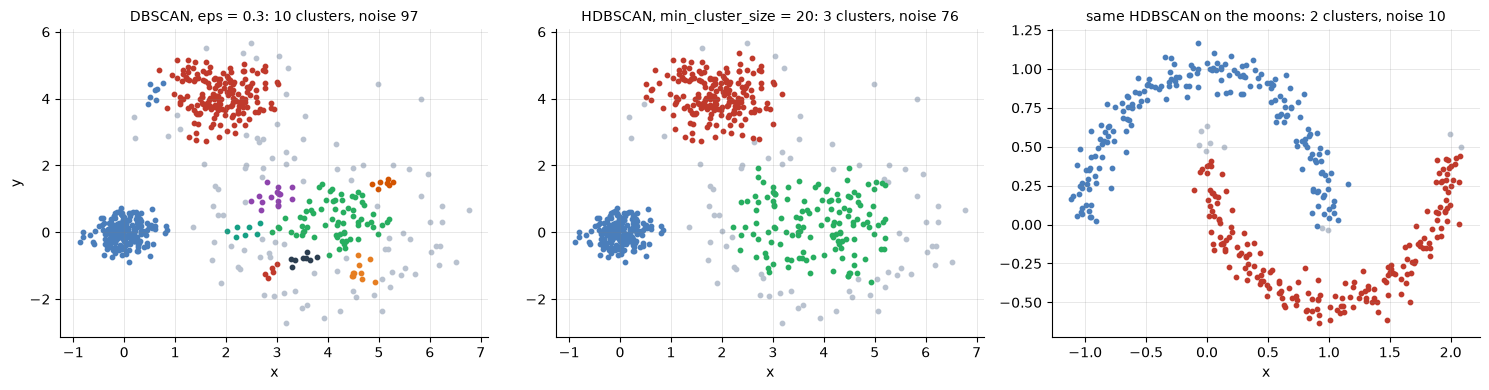

In [21]:
from sklearn.cluster import HDBSCAN

varied_array, _ = make_blobs(
    n_samples=600,
    centers=[[0, 0], [4, 0], [2, 4]],
    cluster_std=[0.3, 1.2, 0.6],
    random_state=3,
)
toy_varied = pd.DataFrame(varied_array, columns=["x", "y"])

# copy=True leaves our table untouched (and silences a warning about a future default)
dbscan_varied = DBSCAN(eps=0.3, min_samples=MIN_SAMPLES).fit(toy_varied).labels_
hdbscan_varied = HDBSCAN(min_cluster_size=20, copy=True).fit(toy_varied).labels_
hdbscan_moons = HDBSCAN(min_cluster_size=20, copy=True).fit(toy_moons).labels_

runs = [
    ("DBSCAN, eps = 0.3", toy_varied, dbscan_varied),
    ("HDBSCAN, min_cluster_size = 20", toy_varied, hdbscan_varied),
    ("same HDBSCAN on the moons", toy_moons, hdbscan_moons),
]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (title, points, labels) in zip(axes, runs):
    draw_clusters(ax, points, labels)
    found_clusters = len(set(labels) - {-1})
    noise_points = int((labels == -1).sum())
    ax.set_title(
        f"{title}: {found_clusters} clusters, noise {noise_points}",
        fontsize=10,
    )
    ax.set_xlabel("x")
    make_ax_better(ax)
axes[0].set_ylabel("y")
plt.tight_layout()
plt.show()

- **DBSCAN** with one radius can't serve a tight blob and a loose one at once: the loose blob falls apart into crumbs and noise.
- **HDBSCAN** finds all three blobs, and on the moons the same setting finds the two moons. Nothing was tuned between the two pictures.

One detail worth knowing. HDBSCAN has a second setting, `min_samples`: how many neighbours make a point part of a crowd (the same idea as in DBSCAN). If you don't set it, it copies `min_cluster_size`. So a large `min_cluster_size` also makes HDBSCAN strict about density, and many points turn into noise. **If too much is noise, lower `min_samples` first** (try it in **Try it 3**).

**In practice:** start with HDBSCAN when you don't know how many groups there are or what shape they have. Demo 3 uses it on complaint texts.

## 8. A third idea: a family tree (hierarchical clustering)

**Agglomerative clustering** starts with every point as its own group. At each step it merges the two closest groups, until one group is left. The record of merges is a tree called a **dendrogram**: the height of each joint shows how far apart the two merged groups were. To get k groups, cut the tree at a height where it has k branches. One tree gives you every k at once.

"Closest groups" needs a rule. **Ward** (the default in scikit-learn) merges the pair that adds the least spread inside groups, which keeps groups compact, like k-means.

🧪 **Toy example:** our eight points again. `linkage` from SciPy computes the merges, `dendrogram` draws them.

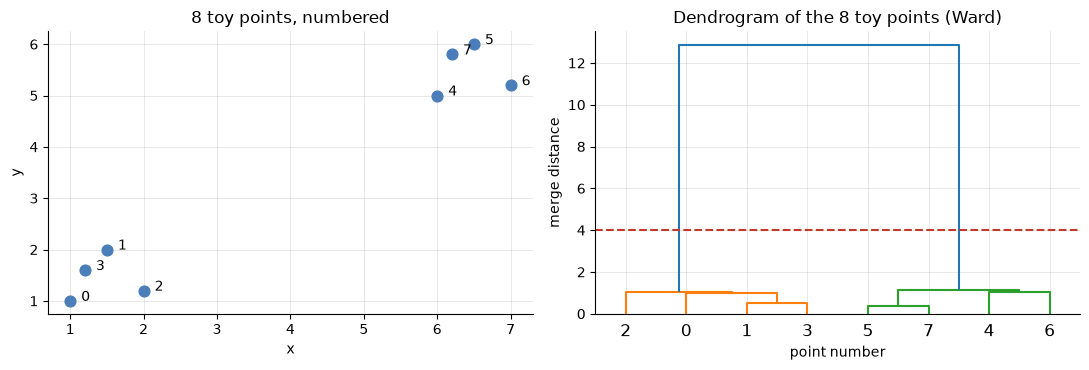

In [22]:
from scipy.cluster.hierarchy import dendrogram, linkage

toy_merges = linkage(toy_points, method="ward")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].scatter(toy_points["x"], toy_points["y"], s=60, color=CLUSTER_COLORS[0])
for row_number in range(len(toy_points)):
    axes[0].text(
        toy_points.loc[row_number, "x"] + 0.15,
        toy_points.loc[row_number, "y"],
        str(row_number),
    )
axes[0].set_title("8 toy points, numbered")
axes[0].set_xlabel("x")
axes[0].set_ylabel("y")
dendrogram(toy_merges, ax=axes[1], color_threshold=4)
axes[1].axhline(4, color=CLUSTER_COLORS[1], linestyle="--")
axes[1].set_title("Dendrogram of the 8 toy points (Ward)")
axes[1].set_xlabel("point number")
axes[1].set_ylabel("merge distance")
for ax in axes:
    make_ax_better(ax)
plt.tight_layout()
plt.show()

Read the tree from the bottom. Neighbouring points merge first, at small heights: the four left points form one branch, the four right points another. The last merge, high up, joins two groups that are far apart. Cut at the dashed line and two branches cross it: two clusters. Cut lower and you get four.

Where it shines: when the nesting itself means something (sector → sub-sector), and when you have tens or hundreds of objects you want to see as a tree. Demo 2 draws the tree of 30 Russian shares. Where it struggles: tens of thousands of points, because it compares every group with every group.

## 9. Four algorithms, four shapes

scikit-learn's documentation has a famous picture: many algorithms run on the same toy shapes, one row per shape. Here is a small version of it, built by hand: four shapes, four algorithms. Each shape is standardized first, and each algorithm gets one setting for all shapes: k for k-means and Ward (the right k for each shape, to be generous), `eps = 0.3` for DBSCAN, `min_cluster_size = 15` for HDBSCAN.

New names in the cell: `make_circles` draws two rings, one inside the other; `rng.uniform(0, 1, size=(400, 2))` draws 400 points spread evenly over a square, a picture with no groups at all; `AgglomerativeClustering` is scikit-learn's hierarchical clustering from section 8 (Ward by default); `ax.set_xticks([])` hides the numbers on an axis, which mean nothing here. For HDBSCAN, `min_samples` is set to DBSCAN's 5 so the two are comparable, and `allow_single_cluster=True` lets it answer "this is all one group": by default HDBSCAN never gives that answer, and on random points it would report several small "crowds" instead.

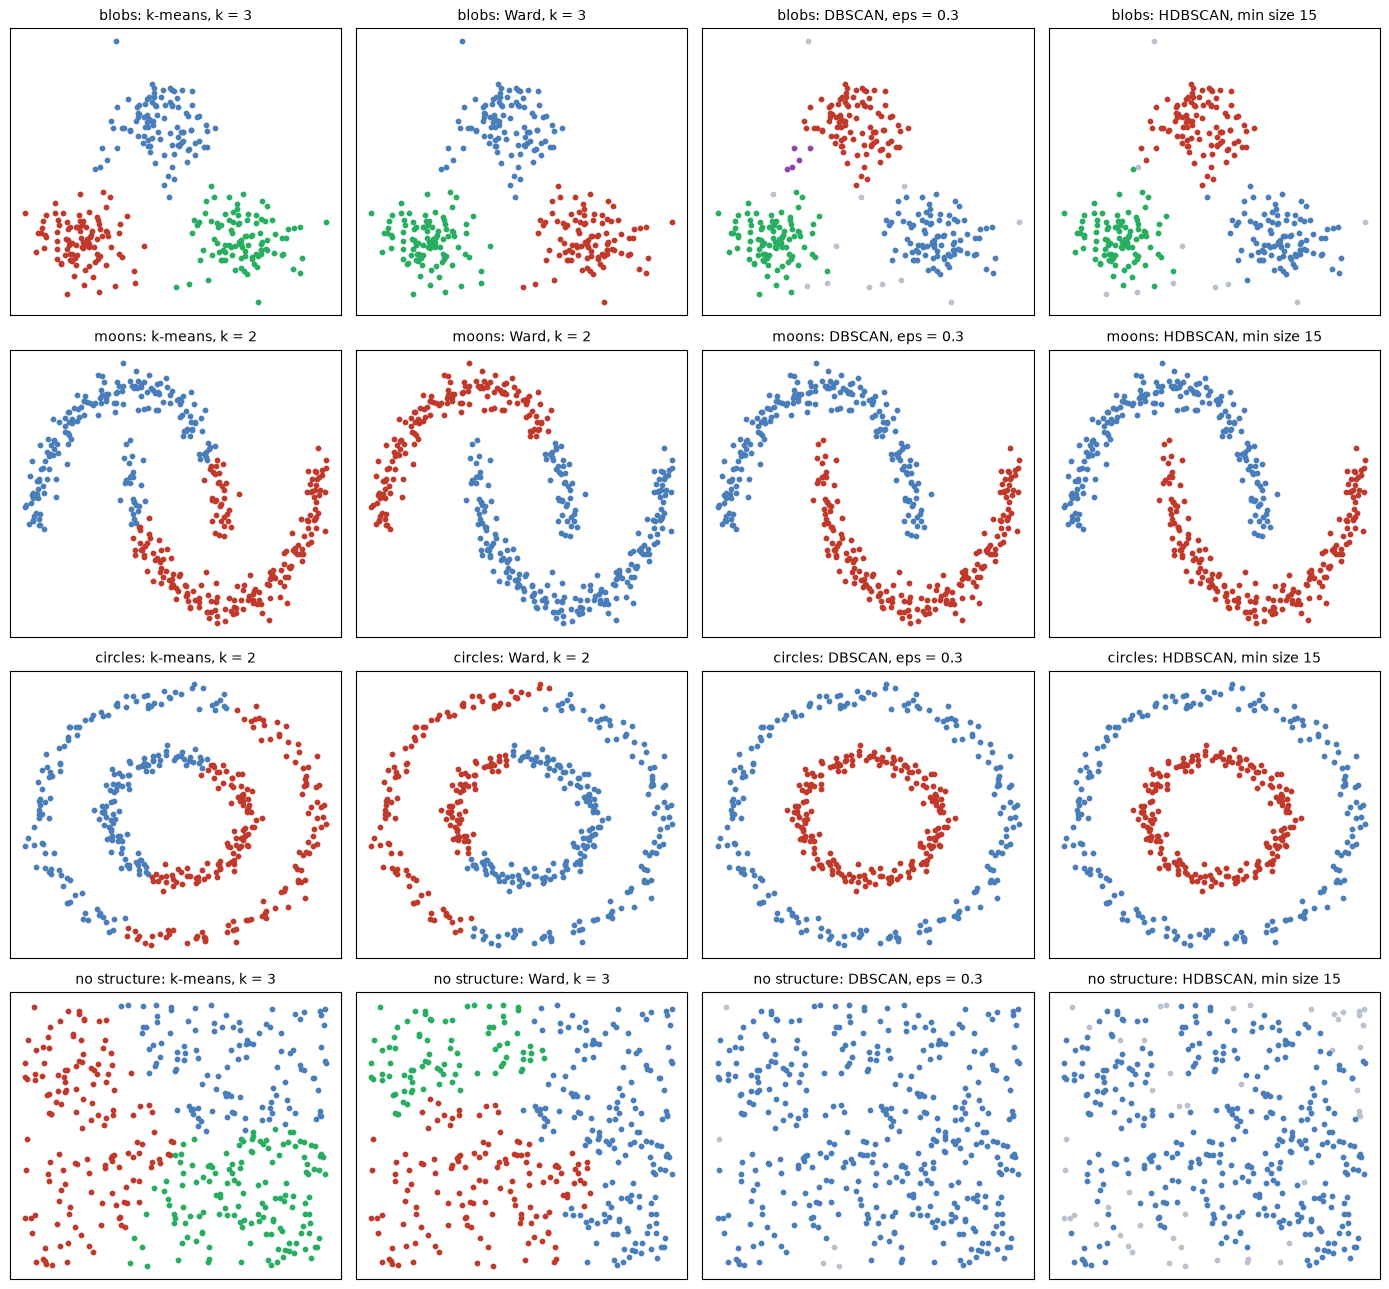

In [23]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.datasets import make_circles

circle_array, _ = make_circles(
    n_samples=400,
    factor=0.5,
    noise=0.05,
    random_state=0,
)
uniform_array = np.random.default_rng(0).uniform(0, 1, size=(400, 2))

# shape name -> (points, the k we give to k-means and Ward)
shapes = {
    "blobs": (blob_array, 3),
    "moons": (moon_array, 2),
    "circles": (circle_array, 2),
    "no structure": (uniform_array, 3),
}

fig, axes = plt.subplots(4, 4, figsize=(14, 13))
for row, (shape_name, (points, k)) in enumerate(shapes.items()):
    scaled_points = pd.DataFrame(
        StandardScaler().fit_transform(points),
        columns=["x", "y"],
    )
    algorithms = {
        f"k-means, k = {k}": KMeans(n_clusters=k, n_init=10, random_state=42),
        f"Ward, k = {k}": AgglomerativeClustering(n_clusters=k),
        "DBSCAN, eps = 0.3": DBSCAN(eps=0.3, min_samples=MIN_SAMPLES),
        "HDBSCAN, min size 15": HDBSCAN(
            min_cluster_size=15,
            min_samples=MIN_SAMPLES,
            allow_single_cluster=True,
            copy=True,
        ),
    }
    for column, (algorithm_name, algorithm) in enumerate(algorithms.items()):
        ax = axes[row, column]
        labels = algorithm.fit(scaled_points).labels_
        draw_clusters(ax, scaled_points, labels)
        ax.set_title(f"{shape_name}: {algorithm_name}", fontsize=10)
        ax.set_xticks([])
        ax.set_yticks([])
plt.tight_layout()
plt.show()

`axes[row, column]` picks one chart from the grid. `enumerate` numbers the rows and columns as we loop (primer).

Read the grid row by row:

- **blobs:** everybody wins (DBSCAN breaks off a tiny crumb of four points). Round, equal groups are what every algorithm expects.
- **moons and circles:** k-means and Ward draw straight borders and cut the shapes wrongly. DBSCAN and HDBSCAN follow the crowds and get them right.
- **no structure:** k-means and Ward still return 3 groups, as in section 3. DBSCAN and HDBSCAN say honestly: one crowd (HDBSCAN calls a few edge points noise). Remove `allow_single_cluster=True` and HDBSCAN finds small crowds in pure noise too: random points always bunch up somewhere. No method is safe from seeing groups that aren't there.

**Every algorithm carries its own idea of what a group is.** k-means: round blobs around centers. DBSCAN and HDBSCAN: dense areas, loners left out. Hierarchical: a tree of merges. Pick the algorithm whose idea matches your data and your question.

📎 **The full picture, 11 algorithms on 6 shapes, and a table of when to use each:** [scikit-learn, Overview of clustering methods](https://scikit-learn.org/stable/modules/clustering.html#overview-of-clustering-methods). The table lists, for every method, its settings, how far it scales and what kind of data it suits. Worth a bookmark.

## 10. What goes wrong in clustering

Not "pick an algorithm and go". The list to keep in mind:

1. **No right answer.** There is nothing to compute accuracy against. You check by reading the groups and naming them.
2. **The algorithm always finds something.** k-means on a cloud without groups still returns k (section 3).
3. **You choose k, eps or the smallest group size.** The advisors can disagree with each other and with the business (section 5).
4. **Units decide for you.** Without scaling, the column with the biggest numbers wins (section 4).
5. **Shape.** k-means only sees round groups (section 9).
6. **Outliers.** One giant point drags a k-means center towards it. DBSCAN and HDBSCAN leave it out as noise.
7. **Instability.** Another start or another sample gives other groups. Re-run with a different `random_state` or on a different half of the data, and compare.
8. **Many columns.** With hundreds of columns, "near" and "far" become almost the same distance. That is why texts and other wide tables are often compressed first (Demo 2 and Demo 3).
9. **A group is not always a topic.** In Demo 3, one group turns out to be the same complaint copied dozens of times.

## Try it yourself

1. Run k-means on the Taiwan pair with k = 4, as the silhouette suggested. Does the fourth group read as anything you could name?
2. In section 4, change the senior salary mean from 130 to 220 and run both versions again. Why do the two runs now agree?
3. Run HDBSCAN on the moons with `min_cluster_size=50`. How many points become noise now? Then add `min_samples=5` and run again: what changed, and why (section 7)?
4. Run HDBSCAN on the Taiwan pair (standardize first). Which companies end up as noise? Do they look unusual on the scatter?
5. 🤖 Ask an assistant: "When would I choose HDBSCAN over k-means for customer data?" Check its answer against section 9: does it mention shape, noise and the choice of k?

In [24]:
# your turn

## Recap

- **Clustering** finds groups without an answer column (**unsupervised**). No accuracy: a good clustering gives groups you can name, act on and get again.
- **k-means**: choose k; assign each point to the nearest center, move centers to the average, repeat. Learned attributes end with `_`: `labels_`, `cluster_centers_`.
- **k-means always returns k groups**, even in a cloud without any. Look before you believe.
- **Scale first**: distances follow the column with the biggest numbers.
- **Choosing k:** inertia (look for the elbow) and silhouette (higher is better) advise; the business decides.
- **DBSCAN**: groups are dense areas; settings `eps` and `min_samples`; no k; loners become noise (`-1`), a simple anomaly detector. Choose `eps` at the bend of the sorted k-distance line.
- **HDBSCAN**: DBSCAN without `eps`, the practical default. One main setting, `min_cluster_size`, the smallest group you care about; copes with groups of different density. Too much noise? Lower `min_samples`.
- **Hierarchical**: merge the closest groups step by step; the dendrogram shows every k at once.
- Every algorithm has its own idea of a group: see the [scikit-learn overview](https://scikit-learn.org/stable/modules/clustering.html#overview-of-clustering-methods).

## ⚡ Extras — power tools, not required

**Gaussian mixture: soft membership.** k-means puts each point in exactly one group. `GaussianMixture` gives each point a probability of belonging to each group, and its groups can be stretched ellipses instead of circles. Useful when the borders between segments are genuinely blurry. `.max(axis=1)` takes the largest number in each row: how sure the model is about its best guess.

In [25]:
from sklearn.mixture import GaussianMixture

mixture = GaussianMixture(n_components=3, random_state=0).fit(toy_varied)
membership = pd.DataFrame(
    mixture.predict_proba(toy_varied),
    columns=["group 0", "group 1", "group 2"],
).round(3)
membership["top_share"] = membership.max(axis=1)

# the five points the mixture is least sure about
membership.sort_values("top_share").head()

,group 0,group 1,group 2,top_share
370,0.604,0.396,0.0,0.604
299,0.613,0.387,0.0,0.613
82,0.644,0.356,0.0,0.644
391,0.754,0.246,0.0,0.754
400,0.192,0.808,0.0,0.808
